# 9 · Different questions, different models

*Part 9. Previously: `08_what_the_graph_buys.ipynb` (the sentence task).*

The study is not about one question type. Four kinds of question are measured,
each probing a different ability:

| task | the model is given | what it tests |
|---|---|---|
| **sentence** | a sentence using the word | reading the word in context |
| **definition** | a dictionary gloss of the sense | matching a meaning description to a sense |
| **collocation** | a typical multi-word phrase | using a phrase as the disambiguating cue |
| **relation** | another sense and a relation (synonym, antonym, hypernym) | following a dictionary link |

The same five answer settings are used everywhere: **B** (search the whole
dictionary), **C** (the word's senses in dictionary order), **D** (the same list
re-ranked by the graph), and the **oracle** control (the gold sense shown).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.width", 220)
REPO = al.REPO_ROOT


def load_run(name):
    try:
        run_id = al.find_run(name)
    except KeyError:
        return None
    cfg = yaml.safe_load(
        (REPO / "runs" / run_id / "config.resolved.yaml").read_text(encoding="utf-8")
    )
    qpath = Path(cfg["questions_path"])
    if not qpath.is_absolute():
        qpath = REPO / qpath
    return al.load_answers(run_id, questions_path=qpath)


V2 = {"luna": "skeleton-cap3-v2", "GaMS 12B": "gams3-12b-api-v2", "GaMS 9B": "gams-9b-api-v2"}
V3 = {"luna": "skeleton-cap3-v3", "GaMS 12B": "gams3-12b-api-v3", "GaMS 9B": "gams-9b-api-v3"}

data = {}
for model in V2:
    frames = [df for df in (load_run(V2[model]), load_run(V3[model])) if df is not None]
    if not frames:
        continue
    d = pd.concat(frames, ignore_index=True)
    d["task"] = np.where(d["question_type"] == "relation", "relation", d["task_type"])
    data[model] = d

print("models:", list(data))
for model, d in data.items():
    print(model, "| questions:", d["question_id"].nunique(), "| tasks:", sorted(d["task"].unique()))

models: ['luna', 'GaMS 12B', 'GaMS 9B']
luna | questions: 80 | tasks: ['collocation', 'definition', 'relation', 'sentence']
GaMS 12B | questions: 80 | tasks: ['collocation', 'definition', 'relation', 'sentence']
GaMS 9B | questions: 80 | tasks: ['collocation', 'definition', 'relation', 'sentence']


## 1 · The same four methods across the four tasks

**How to read it:** the pattern is not "one method wins". B (search the whole
dictionary) is weak on sentences but competitive on definitions - because a
definition query is exactly what a text search can match. C (dictionary order) is
a lottery: it depends on where the right sense sits. D (graph order) is at or near
the top everywhere. The two panels show that the pattern is the same for the
non-native large model (luna) and the native Slovene model (GaMS 12B).

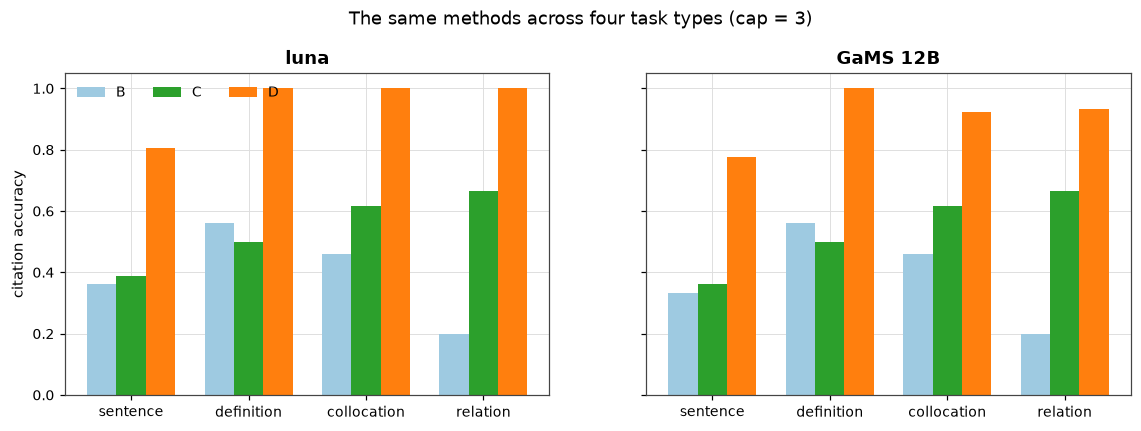

In [2]:
tasks = ["sentence", "definition", "collocation", "relation"]
colors = {"B": "#9ecae1", "C": "#2ca02c", "D": "#ff7f0e"}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, model in zip(axes, ["luna", "GaMS 12B"], strict=True):
    d = data[model]
    x = np.arange(len(tasks))
    for i, variant in enumerate(["B", "C", "D"]):
        vals = [
            d[(d["task"] == task) & (d["variant"] == variant)]["correct"].mean()
            for task in tasks
        ]
        ax.bar(x + (i - 1) * 0.25, vals, width=0.25, color=colors[variant], label=variant)
    ax.set_xticks(x)
    ax.set_xticklabels(tasks)
    ax.set_ylim(0, 1.05)
    ax.set_title(model)
axes[0].set_ylabel("citation accuracy")
axes[0].legend(fontsize=9, ncol=3)
fig.suptitle("The same methods across four task types (cap = 3)", y=1.03)
al.save_figure(fig, "09_tasks_methods")
plt.show()

## 2 · Where the graph helps in the new tasks

The definition and collocation tasks have their own cells: the gold sense is
either visible (shallow) or not (buried), and a collocation is either among the
collocations shown in the context block (`visible`) or further down the
dictionary list (`hidden`) - in the hidden case the model cannot string-match it,
but the graph can.

**How to read it:** for definitions, C is perfect when the sense is visible and
zero when it is buried; D is 1.0 in both. For collocations, the same: D recovers
the buried and the hidden cases. The hidden cells are small (n = 1-5), so treat
them as a signal, not a measurement.

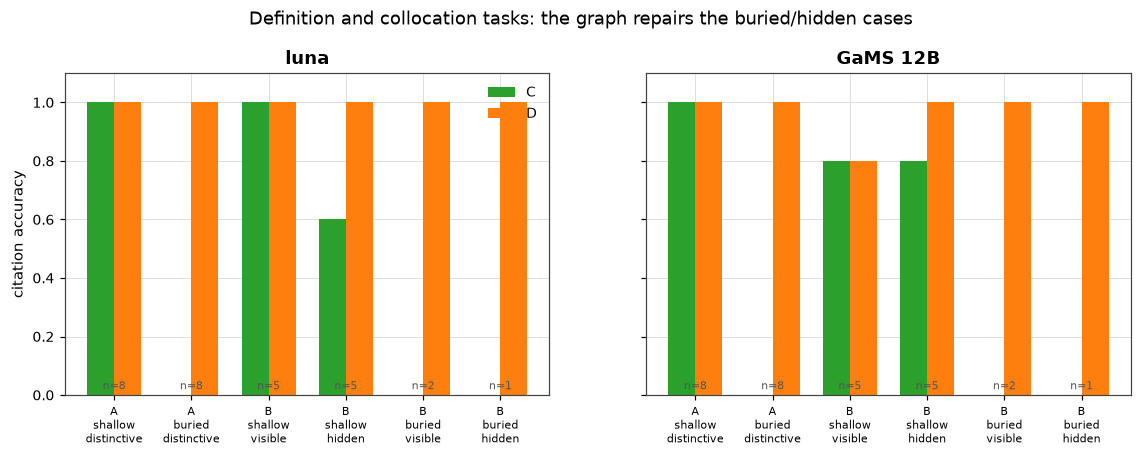

In [3]:
new_cells = [
    "A_shallow_distinctive",
    "A_buried_distinctive",
    "B_shallow_visible",
    "B_shallow_hidden",
    "B_buried_visible",
    "B_buried_hidden",
]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, model in zip(axes, ["luna", "GaMS 12B"], strict=True):
    d = data[model]
    x = np.arange(len(new_cells))
    for i, variant in enumerate(["C", "D"]):
        vals = [
            d[(d["design_cell"] == cell) & (d["variant"] == variant)]["correct"].mean()
            for cell in new_cells
        ]
        ax.bar(x + (i - 0.5) * 0.35, vals, width=0.35, color=colors[variant], label=variant)
    counts = [
        d[d["design_cell"] == cell]["question_id"].nunique() for cell in new_cells
    ]
    for xpos, n in zip(x, counts, strict=True):
        ax.annotate(f"n={n}", (xpos, 0.02), ha="center", fontsize=7, color="#555555")
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace("_", "\n") for c in new_cells], fontsize=7)
    ax.set_ylim(0, 1.1)
    ax.set_title(model)
axes[0].set_ylabel("citation accuracy")
axes[0].legend(fontsize=9)
fig.suptitle("Definition and collocation tasks: the graph repairs the buried/hidden cases", y=1.03)
al.save_figure(fig, "09_new_cells")
plt.show()

## 3 · Native vs non-native: where the difference actually is

The native Slovene models (GaMS 9B/12B) and the non-native large model (luna)
under the same two settings: C (dictionary order) and D (graph order).

**How to read it:** the aggregate picture is **convergence, not a native
advantage**. Under C the three models are nearly identical on every task; under D
they converge further. Being a native Slovene model does **not** make a model
better at using a Slovene dictionary. The one place where the non-native large
model pulls ahead is the **figurative/idiomatic subset of the sentence task**
(notebook 08: its oracle is 1.0 vs 0.6 for GaMS 12B) - that is a language
understanding difference, not a dictionary-access difference, and it is a narrow
subset rather than the aggregate.

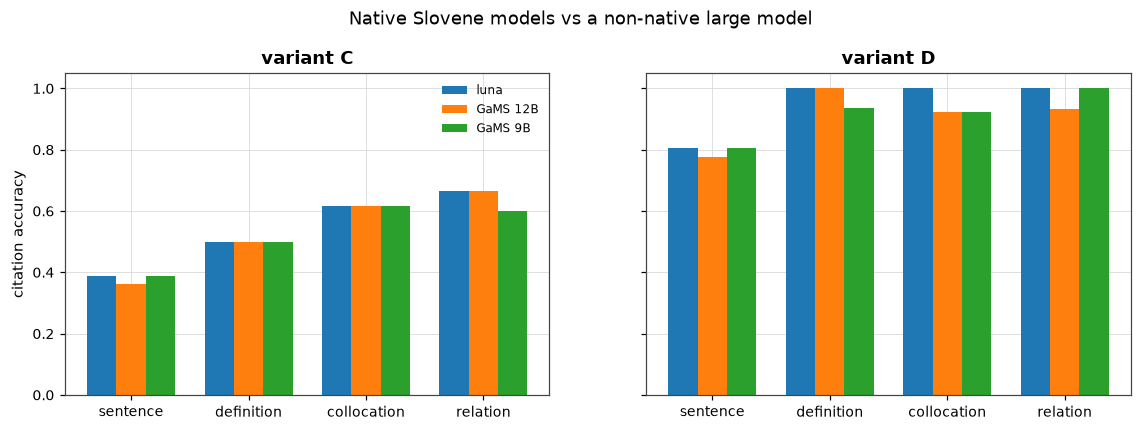

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
models = [m for m in ["luna", "GaMS 12B", "GaMS 9B"] if m in data]
model_colors = {"luna": "#1f77b4", "GaMS 12B": "#ff7f0e", "GaMS 9B": "#2ca02c"}
for ax, variant in zip(axes, ["C", "D"], strict=True):
    x = np.arange(len(tasks))
    for i, model in enumerate(models):
        d = data[model]
        vals = [
            d[(d["task"] == task) & (d["variant"] == variant)]["correct"].mean()
            for task in tasks
        ]
        ax.bar(x + (i - 1) * 0.25, vals, width=0.25, color=model_colors[model], label=model)
    ax.set_xticks(x)
    ax.set_xticklabels(tasks)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"variant {variant}")
axes[0].set_ylabel("citation accuracy")
axes[0].legend(fontsize=8)
fig.suptitle("Native Slovene models vs a non-native large model", y=1.03)
al.save_figure(fig, "09_native_non_native")
plt.show()

## 4 · A warning about the oracle (and why it is not a ceiling)

On the definition/collocation set the graph-ranked list (D) scores **higher than
the oracle** (1.00 vs 0.86 for luna; 0.97 vs 0.86 for GaMS 12B). Nothing is
broken: the oracle is a *different prompt* (the gold sense plus up to four
neighbours, in dictionary order, capped at five), and that longer, less focused
list makes the model pick a neighbour. The oracle is an **empirical control**, not
a mathematical upper bound - the same point as in notebook 07, now with a second
concrete example.

The useful reading stays: `oracle - C/D` measures composition errors; a small
negative difference (D above oracle) is a prompt effect plus single-run noise.

In [5]:
rows = []
for model, d in data.items():
    for task in tasks:
        sub = d[d["task"] == task]
        rows.append(
            {
                "model": model,
                "task": task,
                "C": sub[sub["variant"] == "C"]["correct"].mean(),
                "D": sub[sub["variant"] == "D"]["correct"].mean(),
                "oracle": sub[sub["variant"] == "oracle"]["correct"].mean(),
            }
        )
summary = pd.DataFrame(rows)
display(summary.pivot_table(index=["model", "task"], values=["C", "D", "oracle"]).round(2))

C     D  oracle
model    task                           
GaMS 12B collocation  0.62  0.92    0.69
         definition   0.50  1.00    1.00
         relation     0.67  0.93    1.00
         sentence     0.36  0.78    0.89
GaMS 9B  collocation  0.62  0.92    0.54
         definition   0.50  0.94    1.00
         relation     0.60  1.00    1.00
         sentence     0.39  0.81    0.78
luna     collocation  0.62  1.00    0.69
         definition   0.50  1.00    1.00
         relation     0.67  1.00    1.00
         sentence     0.39  0.81    0.97

## What this adds up to

- **No single method wins across tasks.** B is competitive when the query is a
  definition, weak on sentences; C is a position lottery; D is at or near the top
  everywhere, but it is a *repair* (it re-ranks a list that already contains the
  gold or can be made to contain it), not a reader.
- **The graph's advantage generalises** from sentences to definitions and
  collocations: buried and hidden cases are recovered, visible cases are
  unchanged.
- **Native vs non-native: the aggregate is a tie.** On all four task types the
  native GaMS models and the non-native large model are nearly identical, and
  they converge under D. The non-native model's advantage is confined to the
  **figurative/idiomatic subset** of the sentence task (a composition effect, not
  a dictionary effect). Being a native model is not the same as being better at
  using a dictionary.
- **The Lex model is the missing cell** of this design: a native model trained on
  the dictionary itself. It would tell us whether dictionary training in the
  weights replaces the dictionary in the context - the question this whole study
  is built around.

**Caveats.** The definition/collocation questions are generated from the
dictionary (the gold is the sense that owns the gloss/collocation); they are
cheap and hard to dispute, but still drafts until a lexicographer checks them. The
hidden-collocation cells are small. The sentence cells are constructed around
collocations (notebook 08), so the practical frequency of cues in real text is
still an open question.